In [2]:
%load_ext autoreload
%autoreload 2

0.047714285714285716

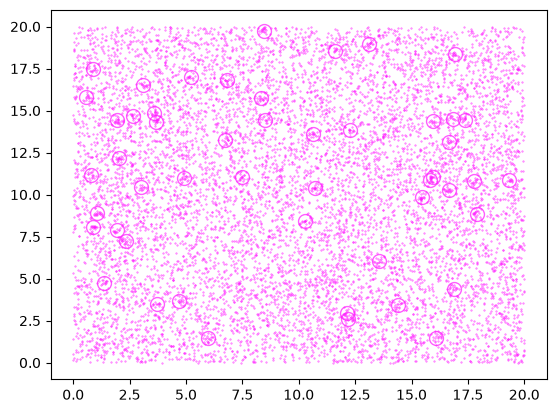

In [ ]:
from prrt_clustering import clean_points_nn_gmm, create_synthetic_point_cloud,plot_points
from sklearn.metrics import f1_score, jaccard_score

points,clusters = create_synthetic_point_cloud(C=1,M=10000)
fig,axes = plot_points(points,ms=1)
plot_points(clusters,ms=20,axes=axes)
len(points[points["noise"]==False]) / len(points)

0.9574235238938975

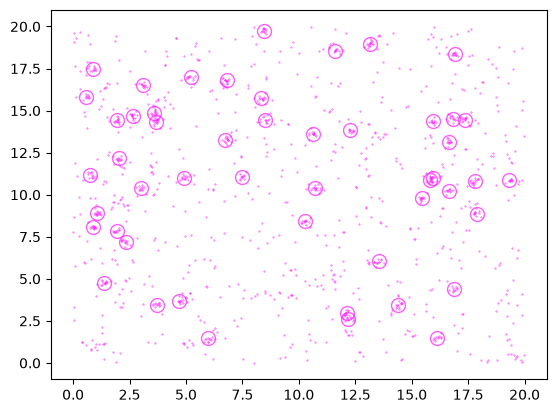

In [11]:
clean = clean_points_nn_gmm(points)
# fig,axes = plot_points(points,ms=1)
fig,axes = plot_points(clean[clean["noise"]==False],ms=1)
plot_points(clusters,ms=20,axes=axes)
f1_score(points["noise"].to_numpy(), clean["noise"].to_numpy())
# print(len(points),len(cle))
# print((clean['noise']==False).sum())

0.9737800810713736

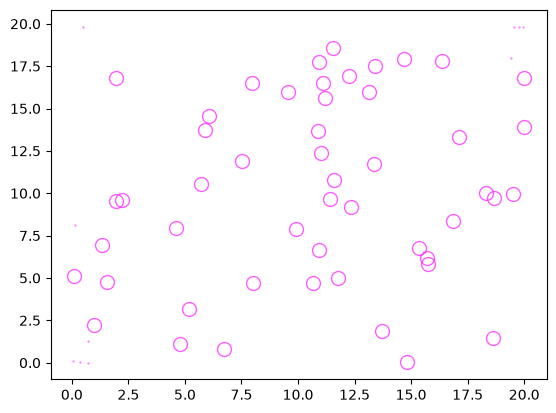

In [ ]:
from prrt_clustering import clean_points_nn_if
clean = clean_points_nn_if(points)
# fig,axes = plot_points(points,ms=1)
# clean = clean_points_outliers(clean[clean['noise']==False])
fig,axes = plot_points(clean[clean["noise"]==False],ms=1)
plot_points(clusters,ms=20,axes=axes)

f1_score(points["noise"].to_numpy(), clean["noise"].to_numpy())


0.7738299436412645

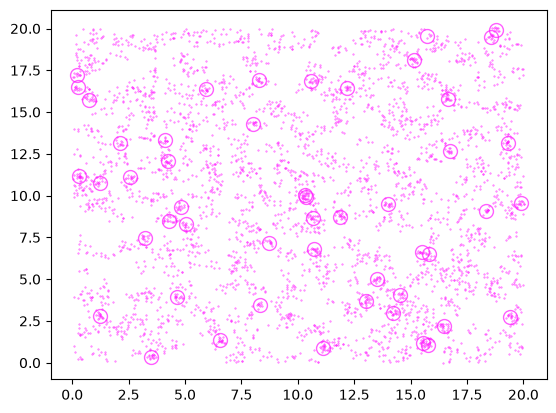

In [6]:
from prrt_clustering import cluster
clean = cluster(points)
# fig,axes = plot_points(points,ms=1)
# clean = clean_points_outliers(clean[clean['noise']==False])
fig,axes = plot_points(clean[clean["noise"]==False],ms=1)
plot_points(clusters,ms=20,axes=axes)
f1_score(points["noise"].to_numpy(), clean["noise"].to_numpy())


0.9554496136774617

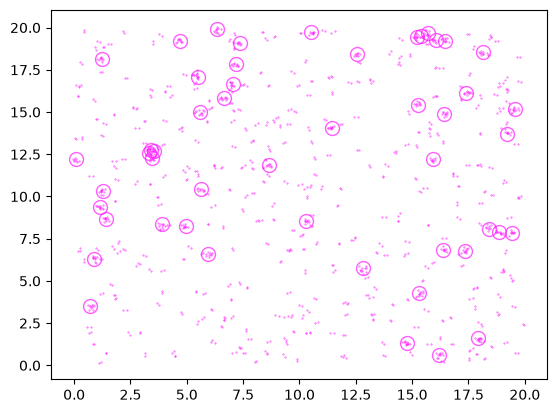

In [13]:
from prrt_clustering import clean_points_besag_gmm

clean = clean_points_besag_gmm(points)
fig,axes = plot_points(clean[clean["noise"]==False],ms=1)
plot_points(clusters,ms=20,axes=axes)
f1_score(points["noise"].to_numpy(), clean["noise"].to_numpy())

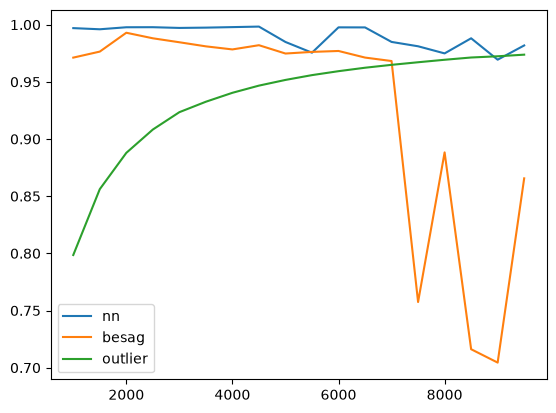

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

score = []
for M in np.arange(1000,10000,500,dtype=int):
    points,clusters = create_synthetic_point_cloud(D=10, C=1, M=M)
    c = len(points[points["noise"]==True]) / len(points)
    rec = {"noise":M}
    clean = clean_points_nn_gmm(points,5)
    rec["nn"] = f1_score(points["noise"].to_numpy(), clean["noise"].to_numpy())
    clean = clean_points_nn_if(points,c)
    rec["if"] = f1_score(points["noise"].to_numpy(), clean["noise"].to_numpy())
    clean = clean_points_besag_gmm(points,.5,5)
    rec["besag"] = f1_score(points["noise"].to_numpy(), clean["noise"].to_numpy())
    score.append(rec)

df = pd.DataFrame.from_records(score)
plt.plot(df["noise"],df["nn"],label="nn")
plt.plot(df["noise"],df["besag"],label="besag")
plt.plot(df["noise"],df["if"],label="if")
plt.legend()